# Teaching an AI to Land a Rocket in Gusty Wind

This notebook builds a 2-D rigid-body rocket simulator from scratch, integrated with RK4, and uses it to test whether a Deep Q-Network (DQN) agent trained with **domain randomisation** lands more reliably under unseen wind than a DQN trained in calm conditions or a classical PID controller. Success rates are estimated from 1,000 Monte Carlo test landings per controller, with 95% confidence intervals. The simulator is verified against free fall, the Tsiolkovsky rocket equation, conservation checks and the RK4 convergence order. [TODO: one-sentence key result.]

> **Work in progress.** The example code below (a Monte Carlo estimate of $\pi$) only shows the expected structure and will be replaced by the rocket model. The notebook must run with *Runtime → Run all* on a fresh Colab runtime. By default it loads pre-trained weights; set `RETRAIN = True` to train from scratch.


In [1]:
# Setup: install anything not already on Colab, then import
# !pip install simpy   # example
import numpy as np
import matplotlib.pyplot as plt

SEED = 42                      # state your seed(s) and keep results reproducible
rng = np.random.default_rng(SEED)
print("numpy", np.__version__)

numpy 2.5.5


## 1. Problem and question

Reusable rockets such as SpaceX's Falcon 9 land vertically under automated guidance, and reinforcement learning is being explored as an alternative to hand-tuned controllers. A learned controller trained in one simulated world may fail when conditions change, and this lack of robustness is a major barrier to trusting AI controllers in safety-critical systems.

**Question:** does training with domain randomisation (randomised mass, gravity and wind in every episode) make a DQN agent land more reliably under *unseen* wind conditions than (a) an agent trained in calm conditions and (b) a classical PID controller?


## 2. Model, assumptions and equations

**Assumptions** (full list and justification in `THEORY.md`)
1. Planar rigid body in the vertical $x$–$y$ plane; uniform gravity.
2. Main engine along the body axis; side thrusters give pure torque.
3. Quadratic drag on the velocity relative to a stochastic horizontal wind.
4. Synthetic, physically plausible parameters for a generic small lander.

**Equations** (state $(x, y, v_x, v_y, \theta, \omega, m)$, $\theta$ measured from vertical)

$$m\dot v_x = -T_m\sin\theta + F_{D,x}, \qquad m\dot v_y = T_m\cos\theta - mg + F_{D,y}, \qquad I(m)\,\dot\omega = \tau_s, \qquad \dot m = -\frac{T}{I_{sp}\,g_0}$$

$$\mathbf F_D = -\tfrac12\rho C_D A\,|\mathbf v_{rel}|\,\mathbf v_{rel}, \qquad \mathbf v_{rel} = (v_x - w,\; v_y), \qquad dw = -\frac{w-\bar w}{\tau_w}dt + \sigma_w\sqrt{2/\tau_w}\,dW_t$$

The equations are integrated with RK4.

**Concepts used:**
- reinforcement learning (DQN) and domain randomisation;
- numerical ODE solvers (RK4 and its error order);
- input modelling and random variate generation (wind gusts, randomised parameters);
- Monte Carlo estimation with confidence intervals (law of large numbers).


## 3. Implementation

### 3.1 Parameters

All values are synthetic and describe a generic small lander (units and reasons are in `THEORY.md`). "Unseen wind" means a mean wind of 10–15 m/s with gusts of 3–5 m/s; training never exceeds 8 m/s and 2 m/s. Mass and gravity stay nominal in the main test, so a drop in success rate comes from wind alone.

In [2]:
from dataclasses import dataclass, replace

@dataclass(frozen=True)
class RocketParams:
    """Nominal vehicle, environment and numerical parameters (SI units, angles in rad)."""
    m0: float = 1000.0        # kg    initial (wet) mass
    m_fuel: float = 100.0     # kg    usable fuel
    T_max: float = 18_000.0   # N     main-engine thrust (on/off)
    T_s: float = 400.0        # N     side-thruster thrust (on/off)
    l_s: float = 2.5          # m     side-thruster lever arm
    L: float = 6.0            # m     rocket length
    Isp: float = 220.0        # s     specific impulse
    g0: float = 9.80665       # m/s^2 standard gravity (defines Isp; never randomised)
    g: float = 9.81           # m/s^2 local gravity
    rho: float = 1.225        # kg/m^3 air density
    CdA: float = 5.0          # m^2   drag coefficient x reference area
    tau_w: float = 2.0        # s     gust correlation time
    dt: float = 0.1           # s     control and RK4 step
    t_max: float = 40.0       # s     episode time limit
    x_lim: float = 150.0      # m     flight area: |x| <= x_lim
    y_lim: float = 200.0      # m     flight area: y <= y_lim

    @property
    def m_dry(self):          # kg
        return self.m0 - self.m_fuel
    @property
    def twr(self):            # initial thrust-to-weight ratio
        return self.T_max / (self.m0 * self.g)
    @property
    def inertia0(self):       # kg m^2, uniform slender rod
        return self.m0 * self.L**2 / 12
    @property
    def max_steps(self):
        return round(self.t_max / self.dt)

@dataclass(frozen=True)
class LandingLimits:
    """Success: every limit holds at first ground contact (y <= 0)."""
    vy_max: float = 2.0               # m/s
    vx_max: float = 1.0               # m/s
    theta_max: float = np.deg2rad(10) # rad
    d_max: float = 10.0               # m, distance from pad centre
    x_pad: float = 0.0                # m

@dataclass(frozen=True)
class InitialConditions:
    """Uniform (low, high) ranges, used in every scenario."""
    x: tuple = (-30.0, 30.0)                              # m
    y: tuple = (80.0, 120.0)                              # m
    vx: tuple = (-3.0, 3.0)                               # m/s
    vy: tuple = (-12.0, -6.0)                             # m/s
    theta: tuple = (-np.deg2rad(5), np.deg2rad(5))        # rad
    omega: tuple = (-0.05, 0.05)                          # rad/s

@dataclass(frozen=True)
class Scenario:
    """Uniform ranges re-sampled at each reset; the sign of the mean wind is +/-1, p = 0.5."""
    name: str
    wind_abs: tuple = (0.0, 0.0)      # m/s   |mean wind|
    gust_sd: tuple = (0.0, 0.0)       # m/s   gust standard deviation
    m0: tuple = (1000.0, 1000.0)      # kg    wet mass (fuel load fixed)
    g: tuple = (9.81, 9.81)           # m/s^2

P, LIMITS, INIT = RocketParams(), LandingLimits(), InitialConditions()

CALM = Scenario("calm")                                                  # trains the calm DQN
DR_TRAIN = Scenario("domain randomisation", (0.0, 8.0), (0.0, 2.0),      # trains the robust DQN
                    (900.0, 1100.0), (9.78, 9.83))   # g: range over the Earth's surface
UNSEEN = Scenario("unseen wind", (10.0, 15.0), (3.0, 5.0))               # main test: nominal m0 and g

N_TEST = 1000           # test episodes per controller
TEST_SEED = 2026        # same episodes for all three controllers
TRAIN_SEEDS = (0, 1, 2, 3, 4)  # independent DQN training runs

In [3]:
# Plausibility checks on the parameters
twr_worst = P.T_max / (DR_TRAIN.m0[1] * DR_TRAIN.g[1])
alpha0 = P.T_s * P.l_s / P.inertia0
mdot = P.T_max / (P.Isp * P.g0)
dv = P.Isp * P.g0 * np.log(P.m0 / P.m_dry)
wind_acc = 0.5 * P.rho * P.CdA * UNSEEN.wind_abs[1]**2 / P.m0   # wind push on a rocket at rest

print(f"thrust-to-weight: {P.twr:.2f} nominal, {twr_worst:.2f} worst case")
print(f"inertia {P.inertia0:.0f} kg m^2, side-thruster angular acceleration {alpha0:.3f} rad/s^2")
print(f"main-engine burn {mdot:.2f} kg/s -> {P.m_fuel/mdot:.1f} s of thrust, delta-v {dv:.0f} m/s")
print(f"acceleration from a {UNSEEN.wind_abs[1]:.0f} m/s wind: {wind_acc:.2f} m/s^2 "
      f"(lean {np.rad2deg(np.arctan(wind_acc / P.g)):.1f} deg)")

assert twr_worst > 1.2, "cannot brake in the worst case"
assert dv > 2 * (abs(INIT.vy[0]) + P.g * 10), "too little fuel for a 10 s descent with a factor of 2"
assert np.arctan(wind_acc / P.g) < LIMITS.theta_max, "steady wind needs more lean than landing allows"
assert UNSEEN.wind_abs[0] > DR_TRAIN.wind_abs[1], "test mean wind overlaps training"
assert UNSEEN.gust_sd[0] > DR_TRAIN.gust_sd[1], "test gusts overlap training"
print("PASS: parameters are plausible and unseen wind lies outside the training range")

thrust-to-weight: 1.83 nominal, 1.66 worst case
inertia 3000 kg m^2, side-thruster angular acceleration 0.333 rad/s^2
main-engine burn 8.34 kg/s -> 12.0 s of thrust, delta-v 227 m/s
acceleration from a 15 m/s wind: 0.69 m/s^2 (lean 4.0 deg)
PASS: parameters are plausible and unseen wind lies outside the training range


### 3.2 Rigid-body dynamics and RK4

States are stored as a batch of shape $(n, 7)$, so many episodes advance in one NumPy call. Gravity and dry mass are passed per episode because domain randomisation varies them.

In [4]:
# Discrete actions: (main engine, side command); side: 0 none, +1 anticlockwise, -1 clockwise
ACTIONS = np.array([(u_m, u_s) for u_m in (0, 1) for u_s in (0, 1, -1)], dtype=float)
N_ACTIONS = len(ACTIONS)

def deriv(s, main, side, wind, g, m_dry, p=P):
    """ds/dt for a batch of states, shape (n, 7): x, y, vx, vy, theta, omega, m.
    main, side, wind, g and m_dry are scalars or arrays of shape (n,)."""
    x, y, vx, vy, th, om, m = s.T
    fuel_left = m > m_dry + 1e-9
    T = p.T_max * main * fuel_left                       # main thrust [N]
    S = p.T_s * side * fuel_left                         # signed side thrust [N]
    v_rel_x = vx - wind
    drag = 0.5 * p.rho * p.CdA * np.hypot(v_rel_x, vy)   # drag force / relative speed [kg/s]
    ax = (-T * np.sin(th) - drag * v_rel_x) / m
    ay = (T * np.cos(th) - drag * vy) / m - g
    alpha = S * p.l_s / (m * p.L**2 / 12)                # torque / I(m)
    mdot = -(T + np.abs(S)) / (p.Isp * p.g0)
    return np.stack([vx, vy, ax, ay, om, alpha, mdot], axis=1)

def rk4_step(s, main, side, wind, g, m_dry, dt=P.dt, p=P):
    """Classical fourth-order Runge-Kutta; controls and wind are held over the step."""
    f = lambda z: deriv(z, main, side, wind, g, m_dry, p)
    k1 = f(s)
    k2 = f(s + 0.5 * dt * k1)
    k3 = f(s + 0.5 * dt * k2)
    k4 = f(s + dt * k3)
    out = s + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    out[:, 6] = np.maximum(out[:, 6], m_dry)             # a step cannot burn fuel it does not have
    return out

def euler_step(s, main, side, wind, g, m_dry, dt=P.dt, p=P):
    """Forward Euler (first order), used only for comparison in the verification."""
    return s + dt * deriv(s, main, side, wind, g, m_dry, p)

### 3.3 Wind and episodes

The wind follows the exact Ornstein–Uhlenbeck update. An episode ends in success or crash at ground contact, or when the rocket leaves the flight area, runs out of fuel or exceeds the time limit.

In [5]:
FLYING, SUCCESS, CRASH, OUT_OF_AREA, OUT_OF_FUEL, TIMEOUT = range(6)
OUTCOMES = ["flying", "success", "crash", "out of area", "out of fuel", "timeout"]

def ou_step(w, w_mean, gust_sd, xi, dt=P.dt, tau=P.tau_w):
    """Exact one-step update of the Ornstein-Uhlenbeck wind; xi ~ N(0, 1)."""
    a = np.exp(-dt / tau)
    return w_mean + (w - w_mean) * a + gust_sd * np.sqrt(1 - a * a) * xi

def is_success(s, lim=LIMITS):
    """The landing definition, applied to states at ground contact."""
    return ((np.abs(s[:, 3]) <= lim.vy_max) & (np.abs(s[:, 2]) <= lim.vx_max)
            & (np.abs(s[:, 4]) <= lim.theta_max) & (np.abs(s[:, 0] - lim.x_pad) <= lim.d_max))

class RocketEnv:
    """n independent episodes advanced together. It knows nothing about controllers or rewards.

    Every step draws one gust per episode, including finished ones, so the same seed gives
    the same start states and winds whichever controller is flying."""

    def __init__(self, n, scenario, seed, p=P, init=INIT, lim=LIMITS):
        self.n, self.sc, self.p, self.init, self.lim = n, scenario, p, init, lim
        self.rng = np.random.default_rng(seed)
        self.s = np.zeros((n, 7))
        self.g, self.m_dry, self.w_mean, self.gust_sd, self.w = (np.zeros(n) for _ in range(5))
        self.k = np.zeros(n, dtype=int)
        self.outcome = np.zeros(n, dtype=int)
        self.reset(np.ones(n, dtype=bool))

    def reset(self, mask):
        """Start new episodes where mask is True; returns the states."""
        c, U, sc, i = int(mask.sum()), self.rng.uniform, self.sc, self.init
        m0 = U(*sc.m0, c)
        self.s[mask] = np.column_stack([U(*r, c) for r in (i.x, i.y, i.vx, i.vy, i.theta, i.omega)] + [m0])
        self.m_dry[mask] = m0 - self.p.m_fuel
        self.g[mask] = U(*sc.g, c)
        self.w_mean[mask] = self.rng.choice([-1.0, 1.0], c) * U(*sc.wind_abs, c)
        self.gust_sd[mask] = U(*sc.gust_sd, c)
        self.w[mask] = self.w_mean[mask] + self.gust_sd[mask] * self.rng.standard_normal(c)
        self.k[mask] = 0
        self.outcome[mask] = FLYING
        return self.s.copy()

    def step(self, action):
        """Advance unfinished episodes by one control step; returns (states, outcomes)."""
        live = self.outcome == FLYING
        main, side = ACTIONS[action].T
        old = self.s[live]
        new = rk4_step(old, main[live], side[live], self.w[live], self.g[live], self.m_dry[live], self.p.dt, self.p)

        # state at ground contact: linear interpolation to y = 0 within the last step
        hit = new[:, 1] <= 0
        f = old[hit, 1] / (old[hit, 1] - new[hit, 1])
        new[hit] = old[hit] + f[:, None] * (new[hit] - old[hit])

        self.k[live] += 1
        out = np.zeros(len(new), dtype=int)
        out[self.k[live] >= self.p.max_steps] = TIMEOUT
        out[new[:, 6] <= self.m_dry[live] + 1e-9] = OUT_OF_FUEL
        out[(np.abs(new[:, 0]) > self.p.x_lim) | (new[:, 1] > self.p.y_lim)] = OUT_OF_AREA
        out[hit] = np.where(is_success(new[hit], self.lim), SUCCESS, CRASH)

        self.s[live], self.outcome[live] = new, out
        self.w = ou_step(self.w, self.w_mean, self.gust_sd, self.rng.standard_normal(self.n), self.p.dt, self.p.tau_w)
        return self.s.copy(), self.outcome.copy()

### 3.4 PID controller

The classical baseline is a cascade: a position PID sets a target tilt, a tilt PD with a dead band fires the side thrusters, and a speed loop switches the main engine to follow a descent profile. Its gains are tuned only on the training wind and mass ranges, with a wider gravity range (9.3–10.3 m/s²) than the DQN (9.78–9.83 m/s²), and never on unseen wind. Set `RETUNE_PID = True` to repeat the search (about 20 s).

In [6]:
def action_index(main, side):
    """Index into ACTIONS from main in {0, 1} and side in {-1, 0, +1}."""
    return (3 * main + np.where(side > 0, 1, np.where(side < 0, 2, 0))).astype(int)

@dataclass(frozen=True)
class PIDGains:
    kp_x: float; ki_x: float; kd_x: float      # 1/s^2, 1/s^3, 1/s   position PID -> acceleration
    tilt_max: float                            # rad   largest commanded tilt
    tilt_land: float; y_low: float             # rad, m   smaller tilt limit below height y_low
    kp_th: float; kd_th: float; dead: float    # -, s, rad   tilt PD and its dead band
    v_touch: float; a_brake: float; v_max: float   # m/s, m/s^2, m/s   descent-speed profile

class PIDController:
    """Cascaded PID. It sees the state only: not the wind, the true gravity or the dry mass."""

    def __init__(self, gains, p=P, i_max=300.0):
        self.k, self.p, self.i_max = gains, p, i_max

    def reset(self, n):
        self.integral = np.zeros(n)            # integral of position error [m s]

    def act(self, s):
        k, (x, y, vx, vy, th, om, _) = self.k, s.T
        err = LIMITS.x_pad - x
        # 1. position PID -> horizontal acceleration -> target tilt (left tilt accelerates to -x)
        acc = k.kp_x * err + k.ki_x * self.integral - k.kd_x * vx
        limit = np.where(y < k.y_low, k.tilt_land, k.tilt_max)
        raw = -acc / self.p.g
        target = np.clip(raw, -limit, limit)
        free = np.abs(raw) < limit             # anti-windup: integrate only when not saturated
        self.integral = np.clip(self.integral + err * self.p.dt * free, -self.i_max, self.i_max)
        # 2. tilt PD with dead band -> side thrusters
        u = k.kp_th * (target - th) - k.kd_th * om
        side = np.where(np.abs(u) > k.dead, np.sign(u), 0)
        # 3. speed loop: main engine on when falling faster than the profile
        v_ref = -np.minimum(np.sqrt(k.v_touch**2 + 2 * k.a_brake * np.maximum(y, 0)), k.v_max)
        return action_index(vy < v_ref, side)

def run_episodes(ctrl, n, scenario, seed):
    """Fly n episodes to the end; returns final states, outcomes and fuel used."""
    env = RocketEnv(n, scenario, seed)
    ctrl.reset(n)
    s = env.s.copy()
    m_start = s[:, 6].copy()
    while (env.outcome == FLYING).any():
        s, _ = env.step(ctrl.act(s))
    return s, env.outcome.copy(), m_start - s[:, 6]

In [7]:
# Tuning: random search, then local refinement, on the training wind range only
RETUNE_PID = False
TUNE_SEED, VAL_SEED = 101, 102     # neither is TEST_SEED
PID_TUNE = replace(DR_TRAIN, name="PID tuning", g=(9.3, 10.3))   # same wind and mass, wider gravity range
GAIN_RANGES = dict(kp_x=(0.03, 0.4), ki_x=(0.0, 0.05), kd_x=(0.2, 1.5), tilt_max=(0.1, 0.35),
                   tilt_land=(0.03, 0.17), y_low=(1.0, 20.0), kp_th=(0.5, 4.0), kd_th=(0.5, 5.0),
                   dead=(0.01, 0.15), v_touch=(0.3, 1.6), a_brake=(1.0, 5.0), v_max=(6.0, 16.0))

def success_rate(gains, n, seed):
    return np.mean(run_episodes(PIDController(gains), n, PID_TUNE, seed)[1] == SUCCESS)

def tune_pid(n_random=300, n_refine=400, n=400):
    r = np.random.default_rng(TUNE_SEED)
    lo, hi = np.array(list(GAIN_RANGES.values())).T
    trials = [(success_rate(PIDGains(*v), n, TUNE_SEED), tuple(v))
              for v in lo + (hi - lo) * r.random((n_random, len(lo)))]
    for i in range(n_refine):
        base = np.array(sorted(trials, reverse=True)[r.integers(5)][1])
        scale = 0.12 * 0.1**(i / n_refine)                      # shrinking steps
        v = np.clip(base + scale * (hi - lo) * r.standard_normal(len(lo)) * (r.random(len(lo)) < 0.4), lo, hi)
        trials.append((success_rate(PIDGains(*v), n, TUNE_SEED), tuple(v)))
    top = sorted(set(trials), reverse=True)[:15]
    # the winner is chosen on fresh episodes, so it is not the luckiest of the tuning set
    return max(((success_rate(PIDGains(*v), 3000, VAL_SEED), v) for _, v in top))

# Result of tune_pid() rounded to 3 significant figures
PID_GAINS = PIDGains(kp_x=0.4, ki_x=0.0371, kd_x=1.42, tilt_max=0.269, tilt_land=0.0809, y_low=20.0,
                     kp_th=2.61, kd_th=2.59, dead=0.0587, v_touch=0.861, a_brake=1.0, v_max=9.12)
if RETUNE_PID:
    val, v = tune_pid()
    PID_GAINS = PIDGains(*[float(f"{x:.3g}") for x in v])
    print(f"validation success {val:.4f}", PID_GAINS)

### 3.5 DQN agents

Both agents share the same network, reward, training length and checkpoint rule; only the training scenario differs. Each agent sees the state alone (no wind, gravity or dry mass). Design choices were made on development seeds 100 and 101; the five reported training seeds are separate. The checkpoint is chosen by success on the agent's own training scenario.

In [8]:
import torch
import torch.nn as nn
torch.set_num_threads(1)     # small networks run fastest on one thread

@dataclass(frozen=True)
class DQNConfig:
    n_envs: int = 64            # parallel episodes
    env_steps: int = 60_000     # batched steps (transitions = n_envs * env_steps)
    updates_per_step: int = 2
    batch: int = 256
    buffer: int = 300_000
    warmup: int = 10_000        # transitions before learning starts
    hidden: int = 128
    gamma: float = 0.99
    lr: float = 5e-4            # decays linearly to lr_end
    lr_end: float = 5e-5
    target_every: int = 1000    # updates between target-network copies
    eps_start: float = 1.0
    eps_end: float = 0.02
    eps_frac: float = 0.3       # share of training over which epsilon is annealed
    eval_every: int = 1000      # batched steps between validations
    eval_n: int = 500
    fuel_cost: float = 0.002    # per kg
    bonus: float = 5.0          # landing
    penalty: float = 5.0        # any failure

CFG = DQNConfig()
DQN_VAL_SEED = 103          # picks the checkpoint; neither TEST_SEED nor unseen wind

def observe(s):
    """Scaled state for the network; the second height feature adds resolution near the ground."""
    x, y, vx, vy, th, om, m = s.T
    return np.stack([x / 20, y / 60 - 1, np.exp(-np.maximum(y, 0) / 8), vx / 4, vy / 6,
                     th / 0.2, om / 0.2, (m - 1000) / 100], axis=1).astype(np.float32)

def potential(s):
    """Shaping potential: high when close to the pad, slow and upright."""
    x, y, vx, vy, th, om, _ = s.T
    v_ref = -np.minimum(np.sqrt(1.0 + 2 * 2.0 * np.maximum(y, 0)), 12.0)      # safe descent speed
    return -(np.abs(x - LIMITS.x_pad) / 6 + np.maximum(y, 0) / 50 + np.abs(vx) / 3 * np.exp(-np.maximum(y, 0) / 20)
             + np.abs(vy - v_ref) / 6 + np.abs(th) / 1.0 + np.abs(om) / 1.0)

def reward(s, s2, out, cfg):
    r = potential(s2) - potential(s) - cfg.fuel_cost * (s[:, 6] - s2[:, 6])
    return r + cfg.bonus * (out == SUCCESS) - cfg.penalty * (out > SUCCESS)

def make_net(cfg):
    return nn.Sequential(nn.Linear(8, cfg.hidden), nn.ReLU(), nn.Linear(cfg.hidden, cfg.hidden), nn.ReLU(),
                         nn.Linear(cfg.hidden, N_ACTIONS))

class DQNController:
    """Greedy policy: the action with the largest Q value."""
    def __init__(self, net):
        self.net = net
    def reset(self, n):
        pass
    def act(self, s):
        with torch.no_grad():
            return self.net(torch.from_numpy(observe(s))).argmax(1).numpy()

def train_dqn(scenario, seed, cfg=CFG, verbose=False):
    """Returns the weights with the best validation score on the training scenario, and the history."""
    torch.manual_seed(seed)
    r = np.random.default_rng([seed, 1])
    env = RocketEnv(cfg.n_envs, scenario, [seed, 2])
    q, target = make_net(cfg), make_net(cfg)
    target.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=cfg.lr)
    loss_fn = nn.SmoothL1Loss()
    O, O2 = np.zeros((cfg.buffer, 8), np.float32), np.zeros((cfg.buffer, 8), np.float32)
    A, R, D = np.zeros(cfg.buffer, np.int64), np.zeros(cfg.buffer, np.float32), np.zeros(cfg.buffer, np.float32)
    ptr = size = n_up = 0
    best, history = (-1.0, -np.inf, None), []
    s = env.s.copy()
    for step in range(1, cfg.env_steps + 1):
        frac = step / cfg.env_steps
        eps = max(cfg.eps_end, cfg.eps_start + (cfg.eps_end - cfg.eps_start) * frac / cfg.eps_frac)
        o = observe(s)
        with torch.no_grad():
            a = q(torch.from_numpy(o)).argmax(1).numpy()
        explore = r.random(cfg.n_envs) < eps
        a = np.where(explore, r.integers(0, N_ACTIONS, cfg.n_envs), a)
        s2, out = env.step(a)
        done = out != FLYING
        idx = (ptr + np.arange(cfg.n_envs)) % cfg.buffer
        O[idx], A[idx], R[idx], O2[idx] = o, a, reward(s, s2, out, cfg), observe(s2)
        D[idx] = done & (out != TIMEOUT)       # a timeout is a time limit, not a state, so bootstrap
        ptr, size = (ptr + cfg.n_envs) % cfg.buffer, min(size + cfg.n_envs, cfg.buffer)
        s = env.reset(done) if done.any() else s2

        if size >= cfg.warmup:
            for grp in opt.param_groups:
                grp["lr"] = cfg.lr + (cfg.lr_end - cfg.lr) * frac
            for _ in range(cfg.updates_per_step):
                j = r.integers(0, size, cfg.batch)
                with torch.no_grad():
                    y = torch.from_numpy(R[j]) + cfg.gamma * (1 - torch.from_numpy(D[j])) * target(torch.from_numpy(O2[j])).max(1).values
                qa = q(torch.from_numpy(O[j])).gather(1, torch.from_numpy(A[j])[:, None])[:, 0]
                loss = loss_fn(qa, y)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(q.parameters(), 10.0)
                opt.step()
                n_up += 1
                if n_up % cfg.target_every == 0:
                    target.load_state_dict(q.state_dict())

        if step % cfg.eval_every == 0:
            fs, fo, _ = run_episodes(DQNController(q), cfg.eval_n, scenario, DQN_VAL_SEED)
            rate, score = float(np.mean(fo == SUCCESS)), float(np.mean(potential(fs)))
            history.append((step * cfg.n_envs, rate))
            if (rate, score) > best[:2]:
                best = (rate, score, {k: v.clone() for k, v in q.state_dict().items()})
            if verbose:
                print(scenario.name, seed, step, f"eps {eps:.2f} success {rate:.3f}", flush=True)
    return best[2], np.array(history), best[0]

### 3.6 Trained weights

The weights were trained with the code above and are loaded by default.

In [9]:
import time, urllib.request
from pathlib import Path

RETRAIN = False     # True trains all ten agents from scratch (about 2 min each on a laptop, longer on Colab)
WEIGHTS_URL = "https://raw.githubusercontent.com/nipunmeegoda/rl-rocket-simulator/main/models/dqn_weights.pt"
AGENTS = {"calm DQN": CALM, "robust DQN": DR_TRAIN}

if RETRAIN:
    saved = {}
    for name, sc in AGENTS.items():
        for seed in TRAIN_SEEDS:
            t0 = time.time()
            w, hist, val = train_dqn(sc, seed)
            saved[f"{name} {seed}"] = dict(state=w, history=torch.tensor(hist), val=val)
            print(f"{name}, seed {seed}: validation {val:.3f}, {time.time() - t0:.0f} s", flush=True)
    torch.save(saved, "dqn_weights.pt")
else:
    local = Path("../models/dqn_weights.pt")        # present in a clone of the repository; otherwise download
    if not local.exists():
        local = Path("dqn_weights.pt")
        urllib.request.urlretrieve(WEIGHTS_URL, local)
    saved = torch.load(local, weights_only=True)

def agent(name, seed):
    net = make_net(CFG)
    net.load_state_dict(saved[f"{name} {seed}"]["state"])
    return DQNController(net)

for name in AGENTS:
    print(name, "validation success by seed:", [round(saved[f"{name} {k}"]["val"], 3) for k in TRAIN_SEEDS])

calm DQN validation success by seed: [0.99, 0.986, 0.986, 1.0, 1.0]
robust DQN validation success by seed: [0.988, 1.0, 0.982, 0.994, 0.942]


## 4. Verification

The simulator is tested before any controller uses it. Each check below stops the notebook if it fails.

### 4.1 Analytic results and conservation laws

In [10]:

NO_DRAG = replace(P, CdA=0.0)

def state(x=0, y=100, vx=0, vy=0, th=0, om=0, m=P.m0):
    return np.array([[x, y, vx, vy, th, om, m]], dtype=float)

def fly(s, t_end, dt=P.dt, main=0, side=0, wind=0.0, g=P.g, p=P, step=rk4_step):
    """Trajectory with constant controls; returns states of shape (steps + 1, 7)."""
    traj = [s]
    for _ in range(round(t_end / dt)):
        traj.append(step(traj[-1], main, side, wind, g, P.m_dry, dt, p))
    return np.array(traj)[:, 0]

def check(name, error, tol):
    assert error <= tol, f"FAIL {name}: {error:.2e} > {tol:.0e}"
    print(f"PASS {name}: error {error:.2e} (tolerance {tol:.0e})")

t = P.dt * np.arange(round(5 / P.dt) + 1)

# 1. Free fall: y = y0 + v0 t - g t^2 / 2
tr = fly(state(vy=-8), 5, p=NO_DRAG)
check("free fall, y [m]", np.abs(tr[:, 1] - (100 - 8 * t - 0.5 * P.g * t**2)).max(), 1e-9)

# 2. Tsiolkovsky: delta-v = Isp g0 ln(m0/m1), gravity and drag off
tr = fly(state(), 10, main=1, g=0.0, p=NO_DRAG)
dv = P.Isp * P.g0 * np.log(P.m0 / tr[-1, 6])
check(f"Tsiolkovsky, delta-v = {dv:.2f} m/s (relative)", abs(tr[-1, 3] - dv) / dv, 1e-8)

# 3. Torque-free motion: omega constant with the main engine on
tr = fly(state(om=0.3), 5, main=1)
check("torque-free, omega [rad/s]", np.abs(tr[:, 5] - 0.3).max(), 1e-12)

# 4. Energy conserved without thrust or drag
tr = fly(state(vx=3, vy=5, om=0.2), 5, p=NO_DRAG)
x, y, vx, vy, th, om, m = tr.T
E = 0.5 * m * (vx**2 + vy**2) + 0.5 * (m * P.L**2 / 12) * om**2 + m * P.g * y
check("energy (relative)", np.abs(E / E[0] - 1).max(), 1e-12)

# 5. Side thruster with burning fuel: omega = 12 l_s Isp g0 ln(m0/m) / L^2
tr = fly(state(), 5, side=1, p=NO_DRAG)
om_exact = 12 * P.l_s * P.Isp * P.g0 / P.L**2 * np.log(P.m0 / tr[-1, 6])
check(f"side torque, omega = {om_exact:.4f} rad/s (relative)", abs(tr[-1, 5] / om_exact - 1), 1e-8)

# 6. Quadratic drag: fall from rest, vy = -v_t tanh(g t / v_t)
v_t = np.sqrt(2 * P.m0 * P.g / (P.rho * P.CdA))
tr = fly(state(), 5)
check(f"drag, terminal speed {v_t:.1f} m/s, vy [m/s]", np.abs(tr[:, 3] + v_t * np.tanh(P.g * t / v_t)).max(), 1e-6)

# 7. Fuel never goes below dry mass, and an empty rocket has no thrust
tr = fly(state(), 20, main=1, g=0.0, p=NO_DRAG)
assert tr[-1, 6] == P.m_dry and tr[-1, 3] == tr[-10, 3]
print("PASS empty tank: mass stops at dry mass and the velocity stops changing")

# 8. Batch of 64 = the same 64 episodes one at a time
r = np.random.default_rng(SEED)
s0 = np.column_stack([r.uniform(-20, 20, 64), r.uniform(50, 100, 64), r.normal(0, 3, (64, 2)),
                      r.normal(0, 0.1, (64, 2)), r.uniform(950, 1000, 64)])
a, w, g = ACTIONS[r.integers(0, N_ACTIONS, 64)], r.normal(0, 8, 64), r.uniform(9.3, 10.3, 64)
batch = rk4_step(s0, a[:, 0], a[:, 1], w, g, P.m_dry)
single = np.vstack([rk4_step(s0[i:i+1], a[i, 0], a[i, 1], w[i], g[i], P.m_dry) for i in range(64)])
check("batch vs single", np.abs(batch - single).max(), 1e-10)

# 14. Directions: a left (anticlockwise) tilt thrusts towards -x; wind from the left pushes towards +x
tr = fly(state(th=0.3), 5, main=1, g=0.0, p=NO_DRAG)
dv = P.Isp * P.g0 * np.log(P.m0 / tr[-1, 6])
check("tilted thrust, (vx, vy) [m/s]", np.abs(tr[-1, 2:4] - dv * np.array([-np.sin(0.3), np.cos(0.3)])).max(), 1e-6)
tr = fly(state(), 5, wind=10.0, g=0.0)                       # vx = w - w / (1 + k w t / m)
k_ = 0.5 * P.rho * P.CdA
check("wind push, vx [m/s]", np.abs(tr[:, 2] - (10 - 10 / (1 + k_ * 10 * t / P.m0))).max(), 1e-6)

PASS free fall, y [m]: error 1.14e-13 (tolerance 1e-09)
PASS Tsiolkovsky, delta-v = 187.95 m/s (relative): error 6.05e-14 (tolerance 1e-08)
PASS torque-free, omega [rad/s]: error 0.00e+00 (tolerance 1e-12)
PASS energy (relative): error 1.55e-15 (tolerance 1e-12)
PASS side torque, omega = 1.6674 rad/s (relative): error 2.99e-12 (tolerance 1e-08)
PASS drag, terminal speed 56.6 m/s, vy [m/s]: error 6.15e-08 (tolerance 1e-06)
PASS empty tank: mass stops at dry mass and the velocity stops changing
PASS batch vs single: error 0.00e+00 (tolerance 1e-10)
PASS tilted thrust, (vx, vy) [m/s]: error 5.26e-12 (tolerance 1e-06)
PASS wind push, vx [m/s]: error 3.19e-12 (tolerance 1e-06)


### 4.2 Error orders, wind statistics and episode rules

order: RK4 4.00, Euler 0.94; position error at dt = 0.1: RK4 1.0e-05 m, Euler 5.9e+00 m
wind: mean 12.013 (12), sd 4.001 (4), correlation at 2 s 0.3694 (0.3679)


Monte Carlo RMS error slope -0.493 (expected -0.5)
PASS common random numbers: identical start states and winds for different controllers
PASS landing rule: all four limits applied on both sides


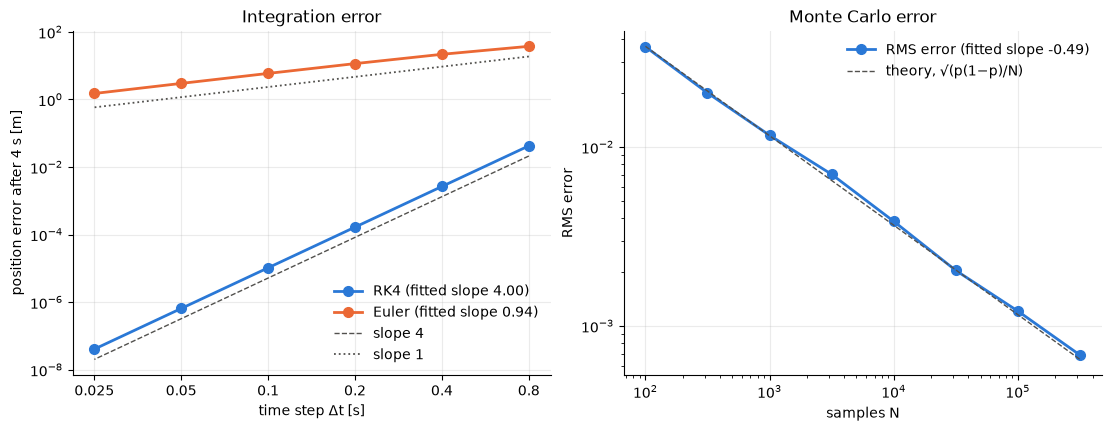

In [11]:
from statistics import NormalDist

# 9. Convergence order: 4 s of powered, turning flight in wind (full model)
dts = 0.8 / 2.0**np.arange(6)
start = state(y=100, vx=3, vy=-10, th=0.1)
kw = dict(main=1, side=1, wind=12.0)
ref = fly(start, 4, dt=1 / 1024, **kw)[-1]
err = {name: np.array([np.linalg.norm(fly(start, 4, dt=h, step=st, **kw)[-1, :2] - ref[:2]) for h in dts])
       for name, st in (("RK4", rk4_step), ("Euler", euler_step))}
slope = {k: np.polyfit(np.log(dts), np.log(e), 1)[0] for k, e in err.items()}
print(f"order: RK4 {slope['RK4']:.2f}, Euler {slope['Euler']:.2f}; "
      f"position error at dt = {P.dt}: RK4 {err['RK4'][3]:.1e} m, Euler {err['Euler'][3]:.1e} m")
assert abs(slope["RK4"] - 4) < 0.2 and abs(slope["Euler"] - 1) < 0.1

# 10. Wind: mean, standard deviation and correlation against theory (4 standard errors)
n, w_mean, sd = 200_000, 12.0, 4.0
r = np.random.default_rng(SEED)
w0 = w_mean + sd * r.standard_normal(n)
w1 = w0
for _ in range(20):                                         # 20 steps = 2 s = tau_w
    w1 = ou_step(w1, w_mean, sd, r.standard_normal(n))
corr, rho_exact = np.corrcoef(w0, w1)[0, 1], np.exp(-20 * P.dt / P.tau_w)
print(f"wind: mean {w1.mean():.3f} (12), sd {w1.std():.3f} (4), correlation at 2 s {corr:.4f} ({rho_exact:.4f})")
assert abs(w1.mean() - w_mean) < 4 * sd / np.sqrt(n)
assert abs(w1.std() - sd) < 4 * sd / np.sqrt(2 * n)
assert abs(corr - rho_exact) < 4 * (1 - rho_exact**2) / np.sqrt(n)

# 11. Monte Carlo error: P(gust > mean + 1 sd) = 1 - Phi(1) is known exactly
p_exact = 1 - NormalDist().cdf(1.0)
Ns = np.logspace(2, 5.5, 8).astype(int)
def mc_rmse(N, reps=200):
    r = np.random.default_rng([SEED, N])
    est = []
    for _ in range(reps):
        w = ou_step(w_mean + sd * r.standard_normal(N), w_mean, sd, r.standard_normal(N))
        est.append(np.mean(w > w_mean + sd))
    return np.sqrt(np.mean((np.array(est) - p_exact)**2))
mc = np.array([mc_rmse(N) for N in Ns])
mc_slope = np.polyfit(np.log(Ns), np.log(mc), 1)[0]
print(f"Monte Carlo RMS error slope {mc_slope:.3f} (expected -0.5)")
assert abs(mc_slope + 0.5) < 0.05

# 12. Common random numbers: the same seed gives the same episodes under different actions
e1, e2 = RocketEnv(50, UNSEEN, TEST_SEED), RocketEnv(50, UNSEEN, TEST_SEED)
assert np.array_equal(e1.s, e2.s)
for _ in range(100):
    e1.step(np.zeros(50, dtype=int)); e2.step(np.full(50, 3))
    assert np.array_equal(e1.w, e2.w)
print("PASS common random numbers: identical start states and winds for different controllers")

# 13. Landing rule: one case just inside each limit, one just outside
eps, L_ = 1e-6, LIMITS
for col, lim in ((3, L_.vy_max), (2, L_.vx_max), (4, L_.theta_max), (0, L_.d_max)):
    for sign in (-1, 1):
        inside, outside = state(y=0), state(y=0)
        inside[0, col], outside[0, col] = sign * (lim - eps), sign * (lim + eps)
        assert is_success(inside)[0] and not is_success(outside)[0]
print("PASS landing rule: all four limits applied on both sides")

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#52514e"
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for name, c in (("RK4", BLUE), ("Euler", ORANGE)):
    ax[0].loglog(dts, err[name], "o-", color=c, lw=2, ms=7, label=f"{name} (fitted slope {slope[name]:.2f})")
ax[0].loglog(dts, 0.5 * err["RK4"][0] * (dts / dts[0])**4, "--", color=INK, lw=1, label="slope 4")
ax[0].loglog(dts, 0.5 * err["Euler"][0] * (dts / dts[0]), ":", color=INK, lw=1.3, label="slope 1")
ax[0].set(xlabel="time step Δt [s]", ylabel="position error after 4 s [m]", title="Integration error")
ax[0].set_xticks(dts, [f"{h:g}" for h in dts]); ax[0].minorticks_off()
ax[1].loglog(Ns, mc, "o-", color=BLUE, lw=2, ms=7, label=f"RMS error (fitted slope {mc_slope:.2f})")
ax[1].loglog(Ns, np.sqrt(p_exact * (1 - p_exact) / Ns), "--", color=INK, lw=1, label="theory, √(p(1−p)/N)")
ax[1].set(xlabel="samples N", ylabel="RMS error", title="Monte Carlo error")
for a_ in ax:
    a_.grid(alpha=0.25); a_.legend(frameon=False); a_.spines[["top", "right"]].set_visible(False)
plt.show()

### 4.3 Controller checks

In [12]:
# 15. Action table and controller directions
for a_, (m_, s_) in enumerate(ACTIONS):
    assert action_index(m_, s_) == a_
pid = PIDController(PID_GAINS); pid.reset(1)
assert ACTIONS[pid.act(state(x=30, vy=-5))[0], 1] == +1         # right of the pad: lean left
pid.reset(1)
assert ACTIONS[pid.act(state(x=-30, vy=-5))[0], 1] == -1        # left of the pad: lean right
pid.reset(1)
assert ACTIONS[pid.act(state(y=100, vy=-30))[0], 0] == 1        # too fast: engine on
pid.reset(1)
assert ACTIONS[pid.act(state(y=100, vy=0))[0], 0] == 0          # too slow: engine off
print("PASS PID: action table, lean direction and engine switching")

PASS PID: action table, lean direction and engine switching


In [13]:
# 16. Loaded weights reproduce the validation rate recorded during training
for name, sc in AGENTS.items():
    for k in TRAIN_SEEDS:
        rate = np.mean(run_episodes(agent(name, k), CFG.eval_n, sc, DQN_VAL_SEED)[1] == SUCCESS)
        assert abs(rate - saved[f"{name} {k}"]["val"]) <= 0.01, (name, k, rate)
print("PASS DQN: all ten weight files reproduce their recorded validation rate")

# 17. Limiting case: no wind, nominal mass and gravity, the same episodes for every controller
for label, ctrl in [("PID", PIDController(PID_GAINS)), ("calm DQN", agent("calm DQN", 0)), ("robust DQN", agent("robust DQN", 0))]:
    (a1, o1, _), (a2, o2, _) = (run_episodes(ctrl, 200, CALM, SEED) for _ in range(2))
    assert np.array_equal(a1, a2) and np.array_equal(o1, o2)      # deterministic: same final states
    assert np.mean(o1 == SUCCESS) > 0.9
    print(f"PASS limiting case {label}: identical on repeat, {100 * np.mean(o1 == SUCCESS):.1f}% of 200 calm landings")

PASS DQN: all ten weight files reproduce their recorded validation rate
PASS limiting case PID: identical on repeat, 100.0% of 200 calm landings
PASS limiting case calm DQN: identical on repeat, 98.5% of 200 calm landings
PASS limiting case robust DQN: identical on repeat, 99.0% of 200 calm landings


## 5. Experiments and results

Every success rate uses 1,000 test episodes (`TEST_SEED = 2026`) with a 95% Wilson confidence interval. All controllers fly the same episodes.

### 5.1 PID baseline

In [14]:
def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion."""
    p_hat, d = k / n, 1 + z * z / n
    mid, half = p_hat + z * z / (2 * n), z * np.sqrt(p_hat * (1 - p_hat) / n + z * z / (4 * n * n))
    return (mid - half) / d, (mid + half) / d

def report(name, ctrl, scenarios=(CALM, DR_TRAIN, UNSEEN), n=N_TEST, seed=TEST_SEED):
    """Success rate with 95% CI, failure counts and the limits broken in crashes."""
    rows = {}
    for sc in scenarios:
        s, out, fuel = run_episodes(ctrl, n, sc, seed)
        k = int((out == SUCCESS).sum())
        lo, hi = wilson(k, n)
        fails = {OUTCOMES[o]: int((out == o).sum()) for o in range(2, 6) if (out == o).any()}
        c = s[out == CRASH]
        broken = dict(vy=int((np.abs(c[:, 3]) > LIMITS.vy_max).sum()), vx=int((np.abs(c[:, 2]) > LIMITS.vx_max).sum()),
                      tilt=int((np.abs(c[:, 4]) > LIMITS.theta_max).sum()),
                      pad=int((np.abs(c[:, 0] - LIMITS.x_pad) > LIMITS.d_max).sum()))
        print(f"{name} | {sc.name:20s} {100*k/n:5.1f}%  95% CI [{100*lo:.1f}, {100*hi:.1f}]  "
              f"median fuel {np.median(fuel):.0f} kg  failures {fails}  crash causes {broken}")
        rows[sc.name] = (k, n, lo, hi)
    return rows

results = {"PID": report("PID", PIDController(PID_GAINS))}

PID | calm                 100.0%  95% CI [99.6, 100.0]  median fuel 66 kg  failures {}  crash causes {'vy': 0, 'vx': 0, 'tilt': 0, 'pad': 0}
PID | domain randomisation 100.0%  95% CI [99.6, 100.0]  median fuel 67 kg  failures {}  crash causes {'vy': 0, 'vx': 0, 'tilt': 0, 'pad': 0}
PID | unseen wind           92.1%  95% CI [90.3, 93.6]  median fuel 66 kg  failures {'crash': 79}  crash causes {'vy': 0, 'vx': 75, 'tilt': 0, 'pad': 7}


### 5.2 DQN agents, one row per training seed

In [15]:
for name in AGENTS:
    for k in TRAIN_SEEDS:
        label = f"{name} seed {k}"
        results[label] = report(label, agent(name, k))
    print()

calm DQN seed 0 | calm                  99.6%  95% CI [99.0, 99.8]  median fuel 50 kg  failures {'crash': 2, 'out of area': 2}  crash causes {'vy': 0, 'vx': 2, 'tilt': 0, 'pad': 0}


calm DQN seed 0 | domain randomisation  51.3%  95% CI [48.2, 54.4]  median fuel 61 kg  failures {'crash': 226, 'out of area': 1, 'out of fuel': 260}  crash causes {'vy': 11, 'vx': 224, 'tilt': 0, 'pad': 12}
calm DQN seed 0 | unseen wind           78.7%  95% CI [76.1, 81.1]  median fuel 55 kg  failures {'crash': 207, 'out of area': 3, 'out of fuel': 3}  crash causes {'vy': 0, 'vx': 74, 'tilt': 2, 'pad': 153}


calm DQN seed 1 | calm                  98.0%  95% CI [96.9, 98.7]  median fuel 48 kg  failures {'crash': 20}  crash causes {'vy': 1, 'vx': 19, 'tilt': 0, 'pad': 0}


calm DQN seed 1 | domain randomisation  84.9%  95% CI [82.5, 87.0]  median fuel 44 kg  failures {'crash': 151}  crash causes {'vy': 14, 'vx': 131, 'tilt': 1, 'pad': 36}
calm DQN seed 1 | unseen wind           87.9%  95% CI [85.7, 89.8]  median fuel 50 kg  failures {'crash': 114, 'out of fuel': 7}  crash causes {'vy': 5, 'vx': 82, 'tilt': 0, 'pad': 37}


calm DQN seed 2 | calm                  98.0%  95% CI [96.9, 98.7]  median fuel 48 kg  failures {'crash': 20}  crash causes {'vy': 0, 'vx': 14, 'tilt': 0, 'pad': 13}


calm DQN seed 2 | domain randomisation  48.2%  95% CI [45.1, 51.3]  median fuel 45 kg  failures {'crash': 499, 'out of area': 7, 'out of fuel': 12}  crash causes {'vy': 287, 'vx': 250, 'tilt': 119, 'pad': 347}
calm DQN seed 2 | unseen wind           64.0%  95% CI [61.0, 66.9]  median fuel 55 kg  failures {'crash': 354, 'out of fuel': 6}  crash causes {'vy': 1, 'vx': 59, 'tilt': 2, 'pad': 306}


... (10 outputs left out)

robust DQN seed 2 | unseen wind           87.6%  95% CI [85.4, 89.5]  median fuel 49 kg  failures {'crash': 123, 'out of fuel': 1}  crash causes {'vy': 3, 'vx': 69, 'tilt': 3, 'pad': 61}
robust DQN seed 3 | calm                 100.0%  95% CI [99.6, 100.0]  median fuel 42 kg  failures {}  crash causes {'vy': 0, 'vx': 0, 'tilt': 0, 'pad': 0}
robust DQN seed 3 | domain randomisation  99.2%  95% CI [98.4, 99.6]  median fuel 43 kg  failures {'crash': 8}  crash causes {'vy': 1, 'vx': 0, 'tilt': 0, 'pad': 7}


robust DQN seed 3 | unseen wind           77.7%  95% CI [75.0, 80.2]  median fuel 45 kg  failures {'crash': 199, 'out of fuel': 24}  crash causes {'vy': 0, 'vx': 67, 'tilt': 0, 'pad': 139}


robust DQN seed 4 | calm                  97.9%  95% CI [96.8, 98.6]  median fuel 43 kg  failures {'crash': 21}  crash causes {'vy': 0, 'vx': 18, 'tilt': 0, 'pad': 4}
robust DQN seed 4 | domain randomisation  93.9%  95% CI [92.2, 95.2]  median fuel 44 kg  failures {'crash': 58, 'out of fuel': 3}  crash causes {'vy': 10, 'vx': 24, 'tilt': 0, 'pad': 26}


robust DQN seed 4 | unseen wind           40.9%  95% CI [37.9, 44.0]  median fuel 45 kg  failures {'crash': 544, 'out of fuel': 47}  crash causes {'vy': 0, 'vx': 301, 'tilt': 37, 'pad': 378}



### 5.3 Comparison

Intervals over training seeds show how much the result depends on the training run. The test episodes are the same for every controller.

In [16]:
T_CRIT = 2.776      # Student t, 4 degrees of freedom, 95%
def seed_rates(name, sc):
    return np.array([100 * results[f"{name} seed {k}"][sc.name][0] / N_TEST for k in TRAIN_SEEDS])

print(f"{'controller':12s} {'scenario':22s} success %, mean over training seeds [95% t-interval], range")
for sc in (CALM, DR_TRAIN, UNSEEN):
    k, n, lo, hi = results["PID"][sc.name]
    print(f"{'PID':12s} {sc.name:22s} {100*k/n:5.1f} [{100*lo:.1f}, {100*hi:.1f}] (Wilson)")
    for name in AGENTS:
        v = seed_rates(name, sc)
        h = T_CRIT * v.std(ddof=1) / np.sqrt(len(v))
        print(f"{name:12s} {sc.name:22s} {v.mean():5.1f} [{max(v.mean()-h, 0):.1f}, {min(v.mean()+h, 100):.1f}]  {v.min():.1f} to {v.max():.1f}")

# Differences in unseen wind (percentage points)
robust, calm_, pid_ = seed_rates("robust DQN", UNSEEN), seed_rates("calm DQN", UNSEEN), 100 * results["PID"][UNSEEN.name][0] / N_TEST
d = robust.mean() - calm_.mean()
v1, v2 = robust.var(ddof=1) / 5, calm_.var(ddof=1) / 5
df = (v1 + v2)**2 / (v1**2 / 4 + v2**2 / 4)
from scipy import stats
h = stats.t.ppf(0.975, df) * np.sqrt(v1 + v2)
print(f"\nunseen wind: robust - calm = {d:+.1f} points, 95% Welch interval [{d-h:+.1f}, {d+h:+.1f}]")
h = T_CRIT * robust.std(ddof=1) / np.sqrt(5)
print(f"unseen wind: robust - PID  = {robust.mean()-pid_:+.1f} points, 95% interval over seeds [{robust.mean()-pid_-h:+.1f}, {robust.mean()-pid_+h:+.1f}]"
      " (PID rate taken as fixed)")

controller   scenario               success %, mean over training seeds [95% t-interval], range
PID          calm                   100.0 [99.6, 100.0] (Wilson)
calm DQN     calm                    99.1 [97.8, 100.0]  98.0 to 100.0
robust DQN   calm                    99.3 [98.2, 100.0]  97.9 to 100.0
PID          domain randomisation   100.0 [99.6, 100.0] (Wilson)
calm DQN     domain randomisation    62.0 [39.9, 84.1]  48.1 to 84.9
robust DQN   domain randomisation    97.9 [95.0, 100.0]  93.9 to 99.7
PID          unseen wind             92.1 [90.3, 93.6] (Wilson)
calm DQN     unseen wind             70.1 [54.2, 85.9]  57.1 to 87.9
robust DQN   unseen wind             65.7 [43.5, 88.0]  40.9 to 87.6



unseen wind: robust - calm = -4.3 points, 95% Welch interval [-27.5, +18.8]
unseen wind: robust - PID  = -26.4 points, 95% interval over seeds [-48.6, -4.1] (PID rate taken as fixed)


### 5.4 Training curves

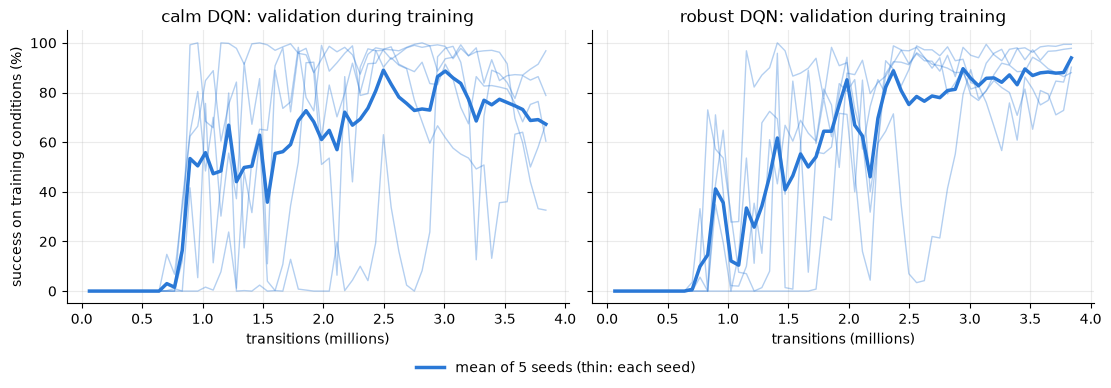

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", sharey=True)
for a_, name in zip(ax, AGENTS):
    for i, k in enumerate(TRAIN_SEEDS):
        h = saved[f"{name} {k}"]["history"].numpy()
        a_.plot(h[:, 0] / 1e6, 100 * h[:, 1], color=BLUE, lw=1, alpha=0.35)
    mean = 100 * np.mean([saved[f"{name} {k}"]["history"].numpy()[:, 1] for k in TRAIN_SEEDS], axis=0)
    a_.plot(h[:, 0] / 1e6, mean, color=BLUE, lw=2.5, label="mean of 5 seeds (thin: each seed)")
    a_.set(title=f"{name}: validation during training", xlabel="transitions (millions)")
    a_.grid(alpha=0.25); a_.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("success on training conditions (%)")
fig.legend(*ax[0].get_legend_handles_labels(), loc="outside lower center", frameon=False)
plt.show()

## 6. Discussion and limitations

[What the results mean for the real-world question; the most important assumptions and their effect; what you would do next.]

**Web demo reference value:** with default settings the web demo should reproduce [value ± tolerance] from section [N].

## 7. References

1. V. Mnih *et al.*, "Human-level control through deep reinforcement learning," *Nature*, vol. 518, no. 7540, pp. 529–533, 2015, doi: 10.1038/nature14236.
2. J. Tobin *et al.*, "Domain randomization for transferring deep neural networks from simulation to the real world," in *Proc. IEEE/RSJ IROS*, 2017, pp. 23–30, doi: 10.1109/IROS.2017.8202133.
3. R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed. MIT Press, 2018.

Full list: `REFERENCES.md`.
